# Non-linear dimensionality reduction on MNIST: t-SNE, UMAP and autoencoders

**Part of the MATH-412 project: t-SNE, UMAP, autoencoders.** PCA is included as the linear baseline from class. Kernel PCA, Isomap, LLE and Laplacian eigenmaps are covered by the rest of the group.

**What this notebook does**
1. Defines evaluation criteria. As the professor pointed out, there is no single benchmark, because each method preserves a different structure.
2. Explains how each method works and what it optimises.
3. **Swiss roll**, a case where the answer is known: does each method unroll the sheet, and does it keep neighbours together?
4. **MNIST**: the same 10,000 images embedded in 2-D by PCA, t-SNE, UMAP and an autoencoder, with the visualisations and the metrics.
5. **Hyperparameters as a bias-variance knob**: t-SNE's perplexity (which sets the Gaussian $\sigma_i$) and UMAP's $k$ = `n_neighbors`.
6. **Autoencoder as a learning problem**: comparison with PCA at the same dimension, overfitting against training-set size, regularisation, and the decoder as a generative map.

**To run:** put the four MNIST files (`train-images.idx3-ubyte`, `train-labels.idx1-ubyte`, `t10k-images.idx3-ubyte`, `t10k-labels.idx1-ubyte`, raw or `.gz`) in `~/Downloads`, or set the environment variable `MNIST_DIR`. Then run:
`pip install numpy pandas matplotlib scikit-learn scipy openTSNE umap-learn torch`.
Everything is seeded (`SEED = 0`). A full run took about 45 minutes on a 2-core machine; a recent laptop should be faster, and the autoencoder parts are much faster on a GPU. Figures and tables are saved in `figures/`.


In [1]:
import os, gzip, struct, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.spatial.distance import pdist
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.model_selection import cross_val_score
from sklearn.datasets import make_swiss_roll
from openTSNE import TSNE                     # pip install openTSNE  (FFT t-SNE, has .transform for new points)
import umap                                   # pip install umap-learn
import torch, torch.nn as nn                  # pip install torch
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 0
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
N_JOBS = 2

# MNIST files (raw idx or .gz). Default: your Downloads folder; override with the MNIST_DIR env variable.
DATA_DIR = Path(os.environ.get("MNIST_DIR", Path.home() / "Downloads"))
OUT_DIR = Path.cwd() / "figures"
OUT_DIR.mkdir(exist_ok=True)


def read_idx(name):
    """Read an MNIST idx file (images -> float32 in [0,1], shape (n, 784); labels -> uint8).
    Accepts both naming styles ('train-images.idx3-ubyte' / 'train-images-idx3-ubyte'), raw or .gz."""
    candidates = [DATA_DIR / (v + ext) for v in (name, name.replace(".idx", "-idx")) for ext in ("", ".gz")]
    p = next((c for c in candidates if c.exists()), None)
    if p is None:
        raise FileNotFoundError(f"{name} not found in {DATA_DIR}")
    with (gzip.open if p.suffix == ".gz" else open)(p, "rb") as f:
        magic = struct.unpack(">I", f.read(4))[0]
        if magic == 2051:                                   # images
            n, r, c = struct.unpack(">III", f.read(12))
            return (np.frombuffer(f.read(), np.uint8).reshape(n, r * c) / 255.0).astype(np.float32)
        n = struct.unpack(">I", f.read(4))[0]               # labels (magic 2049)
        return np.frombuffer(f.read(), np.uint8)


X_train, y_train = read_idx("train-images.idx3-ubyte"), read_idx("train-labels.idx1-ubyte")
X_test, y_test = read_idx("t10k-images.idx3-ubyte"), read_idx("t10k-labels.idx1-ubyte")
print("train", X_train.shape, "test", X_test.shape)

# One fixed 10k sample of the training set is embedded by every method (same data -> fair comparison).
N_SAMPLE = 10_000
sample_idx = rng.choice(len(X_train), N_SAMPLE, replace=False)
X, y = X_train[sample_idx], y_train[sample_idx]
# Held-out data: 5k test images for out-of-sample checks; 10k other training images as AE validation set.
test_idx = rng.choice(len(X_test), 5_000, replace=False)
X_te, y_te = X_test[test_idx], y_test[test_idx]
rest = np.setdiff1d(np.arange(len(X_train)), sample_idx)
val_idx = rng.choice(rest, 10_000, replace=False)
X_val = X_train[val_idx]
print("sample", X.shape, "class counts", np.bincount(y))


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train (60000, 784) test (10000, 784)
sample (10000, 784) class counts [ 991 1135  995 1016  956  907 1026 1040  947  987]


## Evaluation criteria

Each method keeps a different structure, so each criterion below measures one specific property:

| criterion | question it answers | good for |
|---|---|---|
| **trustworthiness** $T(k)$ | Are the $k$ nearest neighbours *in the embedding* also close in the original space? Penalises false neighbours. | local methods (t-SNE, UMAP) |
| **continuity** $C(k)$ | Are the $k$ true nearest neighbours still close in the embedding? Penalises torn neighbourhoods. | local methods |
| **global distance correlation** | Spearman correlation between *all* pairwise distances, before and after. Are far-apart things still far apart? | PCA, MDS, Isomap |
| **$k$-NN accuracy** | How well a $k$-NN classifier predicts the digit from the 2-D coordinates. Labels are used **only** for evaluation. Measured in-sample (5-fold CV) and on new test images. | downstream use |
| **reconstruction error** | How well the image can be rebuilt from the $d$-dimensional code. | PCA, autoencoders |
| **seed stability** | Fraction of shared 10-nearest neighbours between two runs with different random seeds. This is the *variance* of the method. | all stochastic methods |

$$T(k)=1-\frac{2}{nk(2n-3k-1)}\sum_{i=1}^n\sum_{j\in U_k(i)}\big(r(i,j)-k\big)$$

Here $U_k(i)$ is the set of points among the $k$ nearest neighbours of $i$ in the embedding but not in the original space, and $r(i,j)$ is the rank of $j$ among the original-space neighbours of $i$. Continuity $C(k)$ is the same formula with the two spaces swapped. We use $k=10$.


In [2]:
# ---------- evaluation criteria ----------
N_EVAL = 5_000          # trustworthiness/continuity need all pairwise ranks: evaluate on the first 5k points
K_NB = 10               # neighbourhood size for trustworthiness / continuity


def continuity(X_high, Y_low, k=K_NB):
    """Continuity = trustworthiness with the two spaces swapped: are true neighbours kept together?"""
    return trustworthiness(Y_low, X_high, n_neighbors=k)


def global_corr(X_high, Y_low, n=1000, seed=SEED):
    """Spearman correlation between all pairwise distances (high-dim vs embedding) on n points.
    High = large distances (between clusters) are also preserved; local methods are not built for this."""
    i = np.random.default_rng(seed).choice(len(X_high), min(n, len(X_high)), replace=False)
    return spearmanr(pdist(X_high[i]), pdist(Y_low[i])).statistic


def knn_cv_acc(Y_low, labels, k=5):
    """5-fold CV accuracy of a k-NN classifier on the embedding (labels never used to build it)."""
    return cross_val_score(KNeighborsClassifier(k), Y_low, labels, cv=5).mean()


def knn_oos_acc(Y_fit, y_fit, Y_new, y_new, k=5):
    """Out-of-sample: train k-NN on embedded sample, test on embedded *new* images."""
    return KNeighborsClassifier(k).fit(Y_fit, y_fit).score(Y_new, y_new)


def knn_overlap(Y_a, Y_b, k=K_NB):
    """Fraction of shared k-nearest neighbours between two embeddings of the same points
    (two random seeds -> measures the *variance* of the method)."""
    na = NearestNeighbors(n_neighbors=k + 1).fit(Y_a).kneighbors(return_distance=False)[:, 1:]
    nb = NearestNeighbors(n_neighbors=k + 1).fit(Y_b).kneighbors(return_distance=False)[:, 1:]
    return np.mean([len(set(a) & set(b)) / k for a, b in zip(na, nb)])


# ---------- plotting ----------
DIGIT_COLORS = plt.get_cmap("tab10").colors   # 10 classes need 10 hues; each cluster is also labelled with its digit
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9})


def plot_embedding(ax, Y, labels, title, s=1.5, label_clusters=True):
    for d in range(10):
        m = labels == d
        ax.scatter(Y[m, 0], Y[m, 1], s=s, color=DIGIT_COLORS[d], alpha=0.6, linewidths=0, rasterized=True)
        if label_clusters:
            cx, cy = np.median(Y[m], axis=0)
            ax.text(cx, cy, str(d), fontsize=12, weight="bold", ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec=DIGIT_COLORS[d], lw=1.5, alpha=0.85))
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])


# ---------- autoencoder ----------
class AE(nn.Module):
    """Fully connected autoencoder 784 -> 512 -> 256 -> d -> 256 -> 512 -> 784.
    linear=True removes all nonlinearities: the optimum then spans the PCA subspace."""

    def __init__(self, d, n_in=784, hidden=(512, 256), linear=False, sigmoid_out=True):
        super().__init__()
        act = (lambda: nn.Identity()) if linear else (lambda: nn.ReLU())
        enc, dims = [], (n_in,) + hidden
        for a, b in zip(dims[:-1], dims[1:]):
            enc += [nn.Linear(a, b), act()]
        self.encoder = nn.Sequential(*enc, nn.Linear(dims[-1], d))
        dec, rdims = [], (d,) + hidden[::-1]
        for a, b in zip(rdims[:-1], rdims[1:]):
            dec += [nn.Linear(a, b), act()]
        self.decoder = nn.Sequential(*dec, nn.Linear(rdims[-1], n_in), nn.Sigmoid() if (sigmoid_out and not linear) else nn.Identity())

    def forward(self, x):
        return self.decoder(self.encoder(x))


def train_ae(X_tr, X_va, d, steps=4000, batch=128, lr=1e-3, weight_decay=0.0, linear=False,
             early_stop=True, eval_every=100, seed=SEED, hidden=(512, 256), sigmoid_out=True):
    """Minimise mean squared reconstruction error with Adam. Returns model (best val checkpoint if
    early_stop) and the train/val loss history. A fixed number of gradient *steps* is used so that runs
    with different training-set sizes are comparable."""
    torch.manual_seed(seed)
    model = AE(d, n_in=X_tr.shape[1], hidden=hidden, linear=linear, sigmoid_out=sigmoid_out)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    Xt, Xv = torch.tensor(X_tr), torch.tensor(X_va)
    g = torch.Generator().manual_seed(seed)
    hist, best, best_state = [], np.inf, None
    for step in range(1, steps + 1):
        b = Xt[torch.randint(len(Xt), (batch,), generator=g)]
        loss = ((model(b) - b) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        if step % eval_every == 0:
            with torch.no_grad():
                tr = ((model(Xt[:10_000]) - Xt[:10_000]) ** 2).mean().item()
                va = ((model(Xv) - Xv) ** 2).mean().item()
            hist.append((step, tr, va))
            if va < best:
                best, best_state = va, {k: v.clone() for k, v in model.state_dict().items()}
    if early_stop:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(hist, columns=["step", "train_mse", "val_mse"])


def encode(model, Xn):
    with torch.no_grad():
        return model.encoder(torch.tensor(Xn)).numpy()


def recon_mse(model, Xn):
    with torch.no_grad():
        Xt = torch.tensor(Xn)
        return ((model(Xt) - Xt) ** 2).mean().item()


## The three methods

### t-SNE (van der Maaten & Hinton, 2008)
1. **High-dimensional similarities.** Put a Gaussian around each point:
$$p_{j|i}=\frac{\exp(-\|x_i-x_j\|^2/2\sigma_i^2)}{\sum_{k\neq i}\exp(-\|x_i-x_k\|^2/2\sigma_i^2)},\qquad p_{ij}=\frac{p_{j|i}+p_{i|j}}{2n}.$$
$\sigma_i$ is chosen for each point so that the **perplexity** $2^{H(P_i)}$ equals a user value, roughly the "effective number of neighbours". This is the professor's $\sigma$. It adapts to the local density, so dense and sparse regions are treated alike.
2. **Low-dimensional similarities** use a heavy-tailed Student-$t$ (Cauchy) kernel:
$$q_{ij}=\frac{(1+\|y_i-y_j\|^2)^{-1}}{\sum_{k\neq l}(1+\|y_k-y_l\|^2)^{-1}}.$$
The heavy tail solves the *crowding problem*: in 2-D there isn't enough room for all moderately-near points, so they are allowed to sit far apart.
3. **Objective.** Minimise $\mathrm{KL}(P\,\|\,Q)=\sum_{i\neq j}p_{ij}\log\frac{p_{ij}}{q_{ij}}$ by gradient descent, starting with an "early exaggeration" phase.

**Why it is local.** KL is asymmetric. Putting true neighbours far apart (large $p$, small $q$) is very costly, while putting non-neighbours close (small $p$) is almost free. So t-SNE keeps neighbourhoods, but **cluster sizes and distances between clusters carry little meaning**.

**No mapping.** t-SNE optimises the coordinates themselves, not a function. A new point has to be placed by a separate optimisation against the fixed map (`openTSNE.transform`). Cost is $O(n\log n)$ per iteration with Barnes-Hut or FFT approximations.

### UMAP (McInnes, Healy & Melville, 2018)
1. **Weighted $k$-NN graph** with $k$ = `n_neighbors`, the professor's $k$:
$$w_{ij}=\exp\!\Big(-\frac{d(x_i,x_j)-\rho_i}{\sigma_i}\Big),$$
where $\rho_i$ is the distance to the nearest neighbour and $\sigma_i$ solves $\sum_j w_{ij}=\log_2 k$. The weights are symmetrised as $w_{ij}+w_{ji}-w_{ij}w_{ji}$ (a "fuzzy union").
2. **Low-dimensional similarity** $v_{ij}=(1+a\|y_i-y_j\|^{2b})^{-1}$, where $a,b$ are set by `min_dist`. This only controls how tightly points pack.
3. **Objective.** Fuzzy-set cross-entropy
$$\sum_{i\neq j}\Big[w_{ij}\log\frac{w_{ij}}{v_{ij}}+(1-w_{ij})\log\frac{1-w_{ij}}{1-v_{ij}}\Big].$$
The first term attracts neighbours, as in t-SNE. The second term explicitly *repels* non-neighbours, which keeps somewhat more global structure. Optimised by SGD with negative sampling.
4. **Initialisation** with the spectral embedding of the graph, i.e. **Laplacian eigenmaps** (another method in our project). The graph is kept, so new points can be embedded with `transform()`.

### Autoencoder (Hinton & Salakhutdinov, 2006)
An encoder $f_\theta:\mathbb R^{784}\to\mathbb R^d$ and a decoder $g_\phi:\mathbb R^d\to\mathbb R^{784}$ (here two hidden layers of 512 and 256 units, ReLU, sigmoid output) are trained to minimise the reconstruction error
$$\frac1n\sum_{i=1}^n\big\|x_i-g_\phi(f_\theta(x_i))\big\|^2\;\;(+\lambda\|\theta,\phi\|^2).$$
- **Link to PCA:** with linear layers and squared loss, the optimal code spans the top-$d$ principal subspace (Baldi & Hornik, 1989). A non-linear AE is a non-linear generalisation of PCA.
- **Parametric:** it learns explicit maps in both directions. New points are just $f_\theta(x)$, and the decoder can *generate* images from any code.
- **It is a supervised-style learning problem** (input = target), so the course concepts apply directly: training vs validation error, overfitting, weight decay, early stopping, and model capacity ($d$, width, depth).
- It preserves whatever is needed for reconstruction, **not** neighbourhoods. Nothing in the loss asks for clusters to be separated.

| | what it preserves | complexity knob | maps new points? | main pitfall |
|---|---|---|---|---|
| PCA | variance / global linear structure | $d$ | yes (linear) | cannot unfold curved manifolds |
| t-SNE | local neighbourhoods | perplexity ($\sigma_i$) | no (re-optimise) | inter-cluster distances and sizes not meaningful |
| UMAP | local neighbourhoods + some global structure | `n_neighbors` ($k$), `min_dist` | yes | same as t-SNE, milder |
| Autoencoder | information needed to reconstruct | $d$, width, depth, $\lambda$ | yes (encoder) | overfitting, local optima, no neighbourhood guarantee |


## Swiss roll: a case with a known answer

A 2-D sheet rolled up in 3-D (3,000 points). We know each point's true sheet coordinates (position $t$ along the roll and height), so we can check two things separately: are neighbours kept together (trustworthiness and continuity), and is the sheet *unrolled*, i.e. are distances measured along the sheet preserved (Spearman correlation with the true 2-D distances)?


/usr/local/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


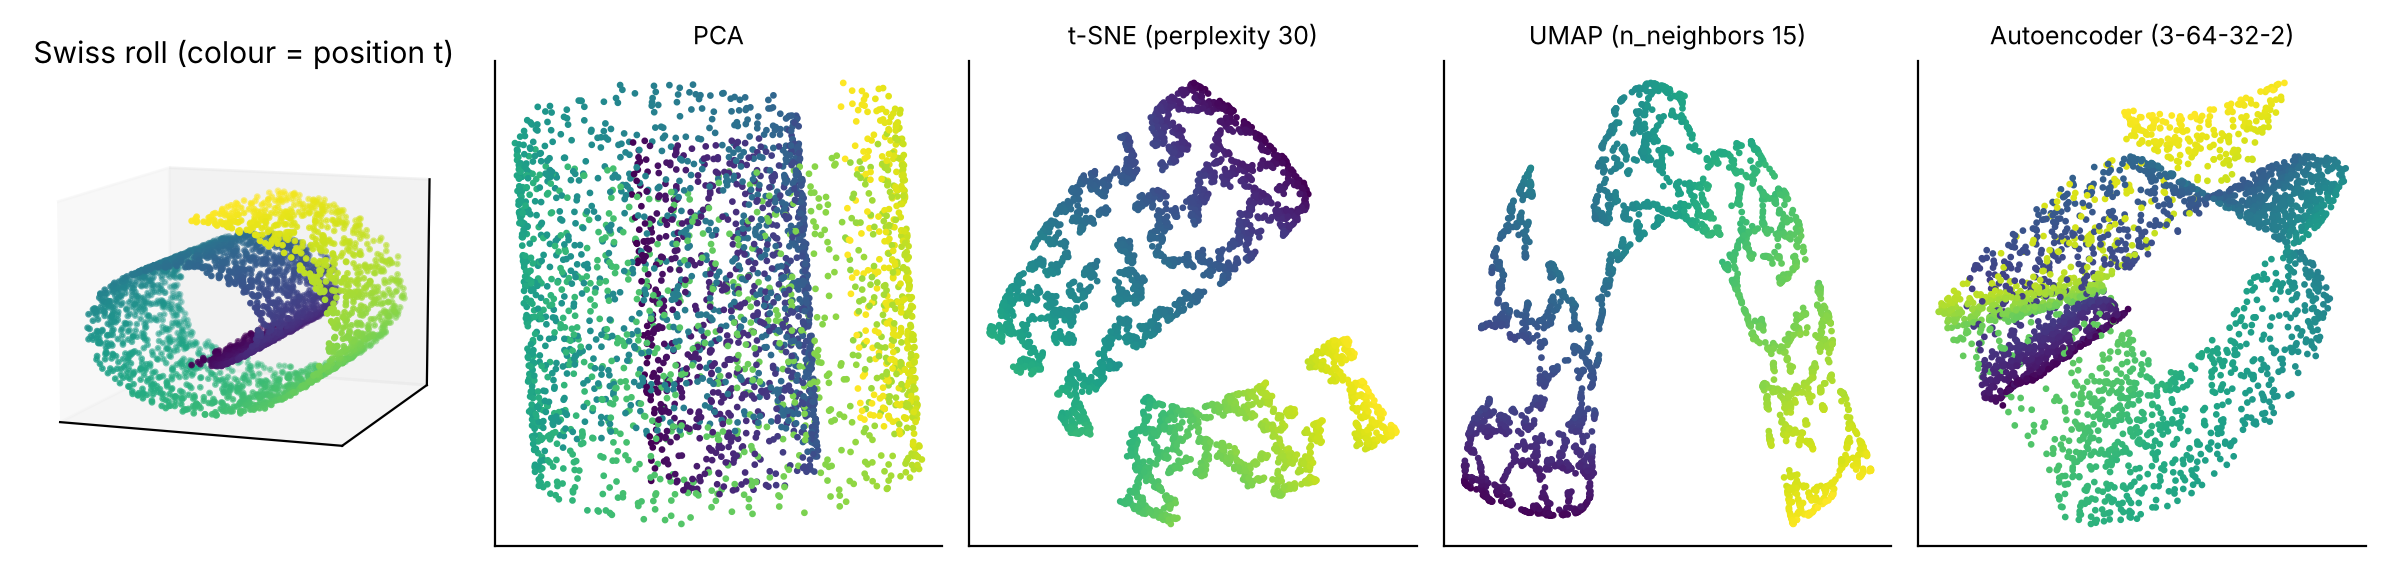

,trustworthiness@10,continuity@10,unrolling (Spearman vs true 2-D distances)
method,,,
PCA,0.861,0.997,0.578
t-SNE (perplexity 30),1.000,0.998,0.330
UMAP (n_neighbors 15),0.999,0.998,0.349
Autoencoder (3-64-32-2),0.987,0.994,0.108


In [3]:
# Swiss roll: a 2-D sheet rolled up in 3-D. We know the true 2-D coordinates (t = position along the roll,
# h = height), so we can check whether each method "unrolls" it (global) and keeps neighbours (local).
Xs, t_roll = make_swiss_roll(3000, noise=0.05, random_state=SEED)
Xs = Xs.astype(np.float32)
intrinsic = np.c_[t_roll, Xs[:, 1]]
Xs_std = ((Xs - Xs.mean(0)) / Xs.std(0)).astype(np.float32)

sr = {}
sr["PCA"] = PCA(2, random_state=SEED).fit_transform(Xs_std)
sr["t-SNE (perplexity 30)"] = np.asarray(TSNE(perplexity=30, n_jobs=N_JOBS, random_state=SEED).fit(Xs_std))
sr["UMAP (n_neighbors 15)"] = umap.UMAP(n_neighbors=15, random_state=SEED).fit_transform(Xs_std)
ae_sr, _ = train_ae(Xs_std[:2500], Xs_std[2500:], d=2, steps=6000, hidden=(64, 32), sigmoid_out=False)
sr["Autoencoder (3-64-32-2)"] = encode(ae_sr, Xs_std)

fig = plt.figure(figsize=(12, 2.9))
ax = fig.add_subplot(1, 5, 1, projection="3d")
ax.scatter(Xs[:, 0], Xs[:, 1], Xs[:, 2], c=t_roll, cmap="viridis", s=2)
ax.set_title("Swiss roll (colour = position t)"); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
ax.view_init(10, -70)
rows = []
for i, (name, Y) in enumerate(sr.items(), start=2):
    ax = fig.add_subplot(1, 5, i)
    ax.scatter(Y[:, 0], Y[:, 1], c=t_roll, cmap="viridis", s=2)
    ax.set_title(name, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    rows.append({"method": name,
                 "trustworthiness@10": trustworthiness(Xs_std, Y, n_neighbors=K_NB),
                 "continuity@10": continuity(Xs_std, Y),
                 "unrolling (Spearman vs true 2-D distances)": global_corr(intrinsic, Y)})
fig.tight_layout(); fig.savefig(OUT_DIR / "swissroll.png", dpi=200); plt.show()
sr_table = pd.DataFrame(rows).set_index("method")
display(sr_table.round(3))


**Why each method works or fails here**
- **PCA** projects onto the two directions of largest variance, which flattens the roll. The layers end up on top of each other: points from different turns become neighbours (trustworthiness 0.86). It still scores best on the unrolling correlation (0.58), because a projection roughly keeps the overall extent. A linear map cannot unfold a curved manifold.
- **t-SNE** keeps neighbourhoods almost perfectly (trustworthiness 1.000, continuity 0.998) but **tears** the sheet into three pieces. The KL objective doesn't care where the pieces go relative to each other, so the unrolling correlation is only 0.33.
- **UMAP** produces **one connected strip ordered by $t$**, with a continuous colour gradient. It keeps the *topology* of the sheet. The strip is bent and its width varies, though, so distances are not preserved (0.35).
- **The autoencoder** (3-64-32-2) has a similar trustworthiness (0.987) but **folds** the sheet, so different parts of the roll overlap in the code (unrolling 0.11). Nothing in the reconstruction loss asks for distances to be preserved, and gradient training from a random start can settle in such a folded local optimum.

**Lessons.** (1) Local criteria are close to 1 for t-SNE and UMAP even though the pictures differ a lot. Local and global criteria must be reported together. (2) None of these three methods is designed to preserve *distances along the manifold*. That is what Isomap does (geodesic distances on the $k$-NN graph), so the Swiss roll is the natural place to compare with that part of the project.


## MNIST: the four methods on the same 10,000 images


variance kept by 50 PCs: 0.826


/tmp/ipykernel_829/839852924.py:16: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  t0 = time.time(); um = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED).fit(X)


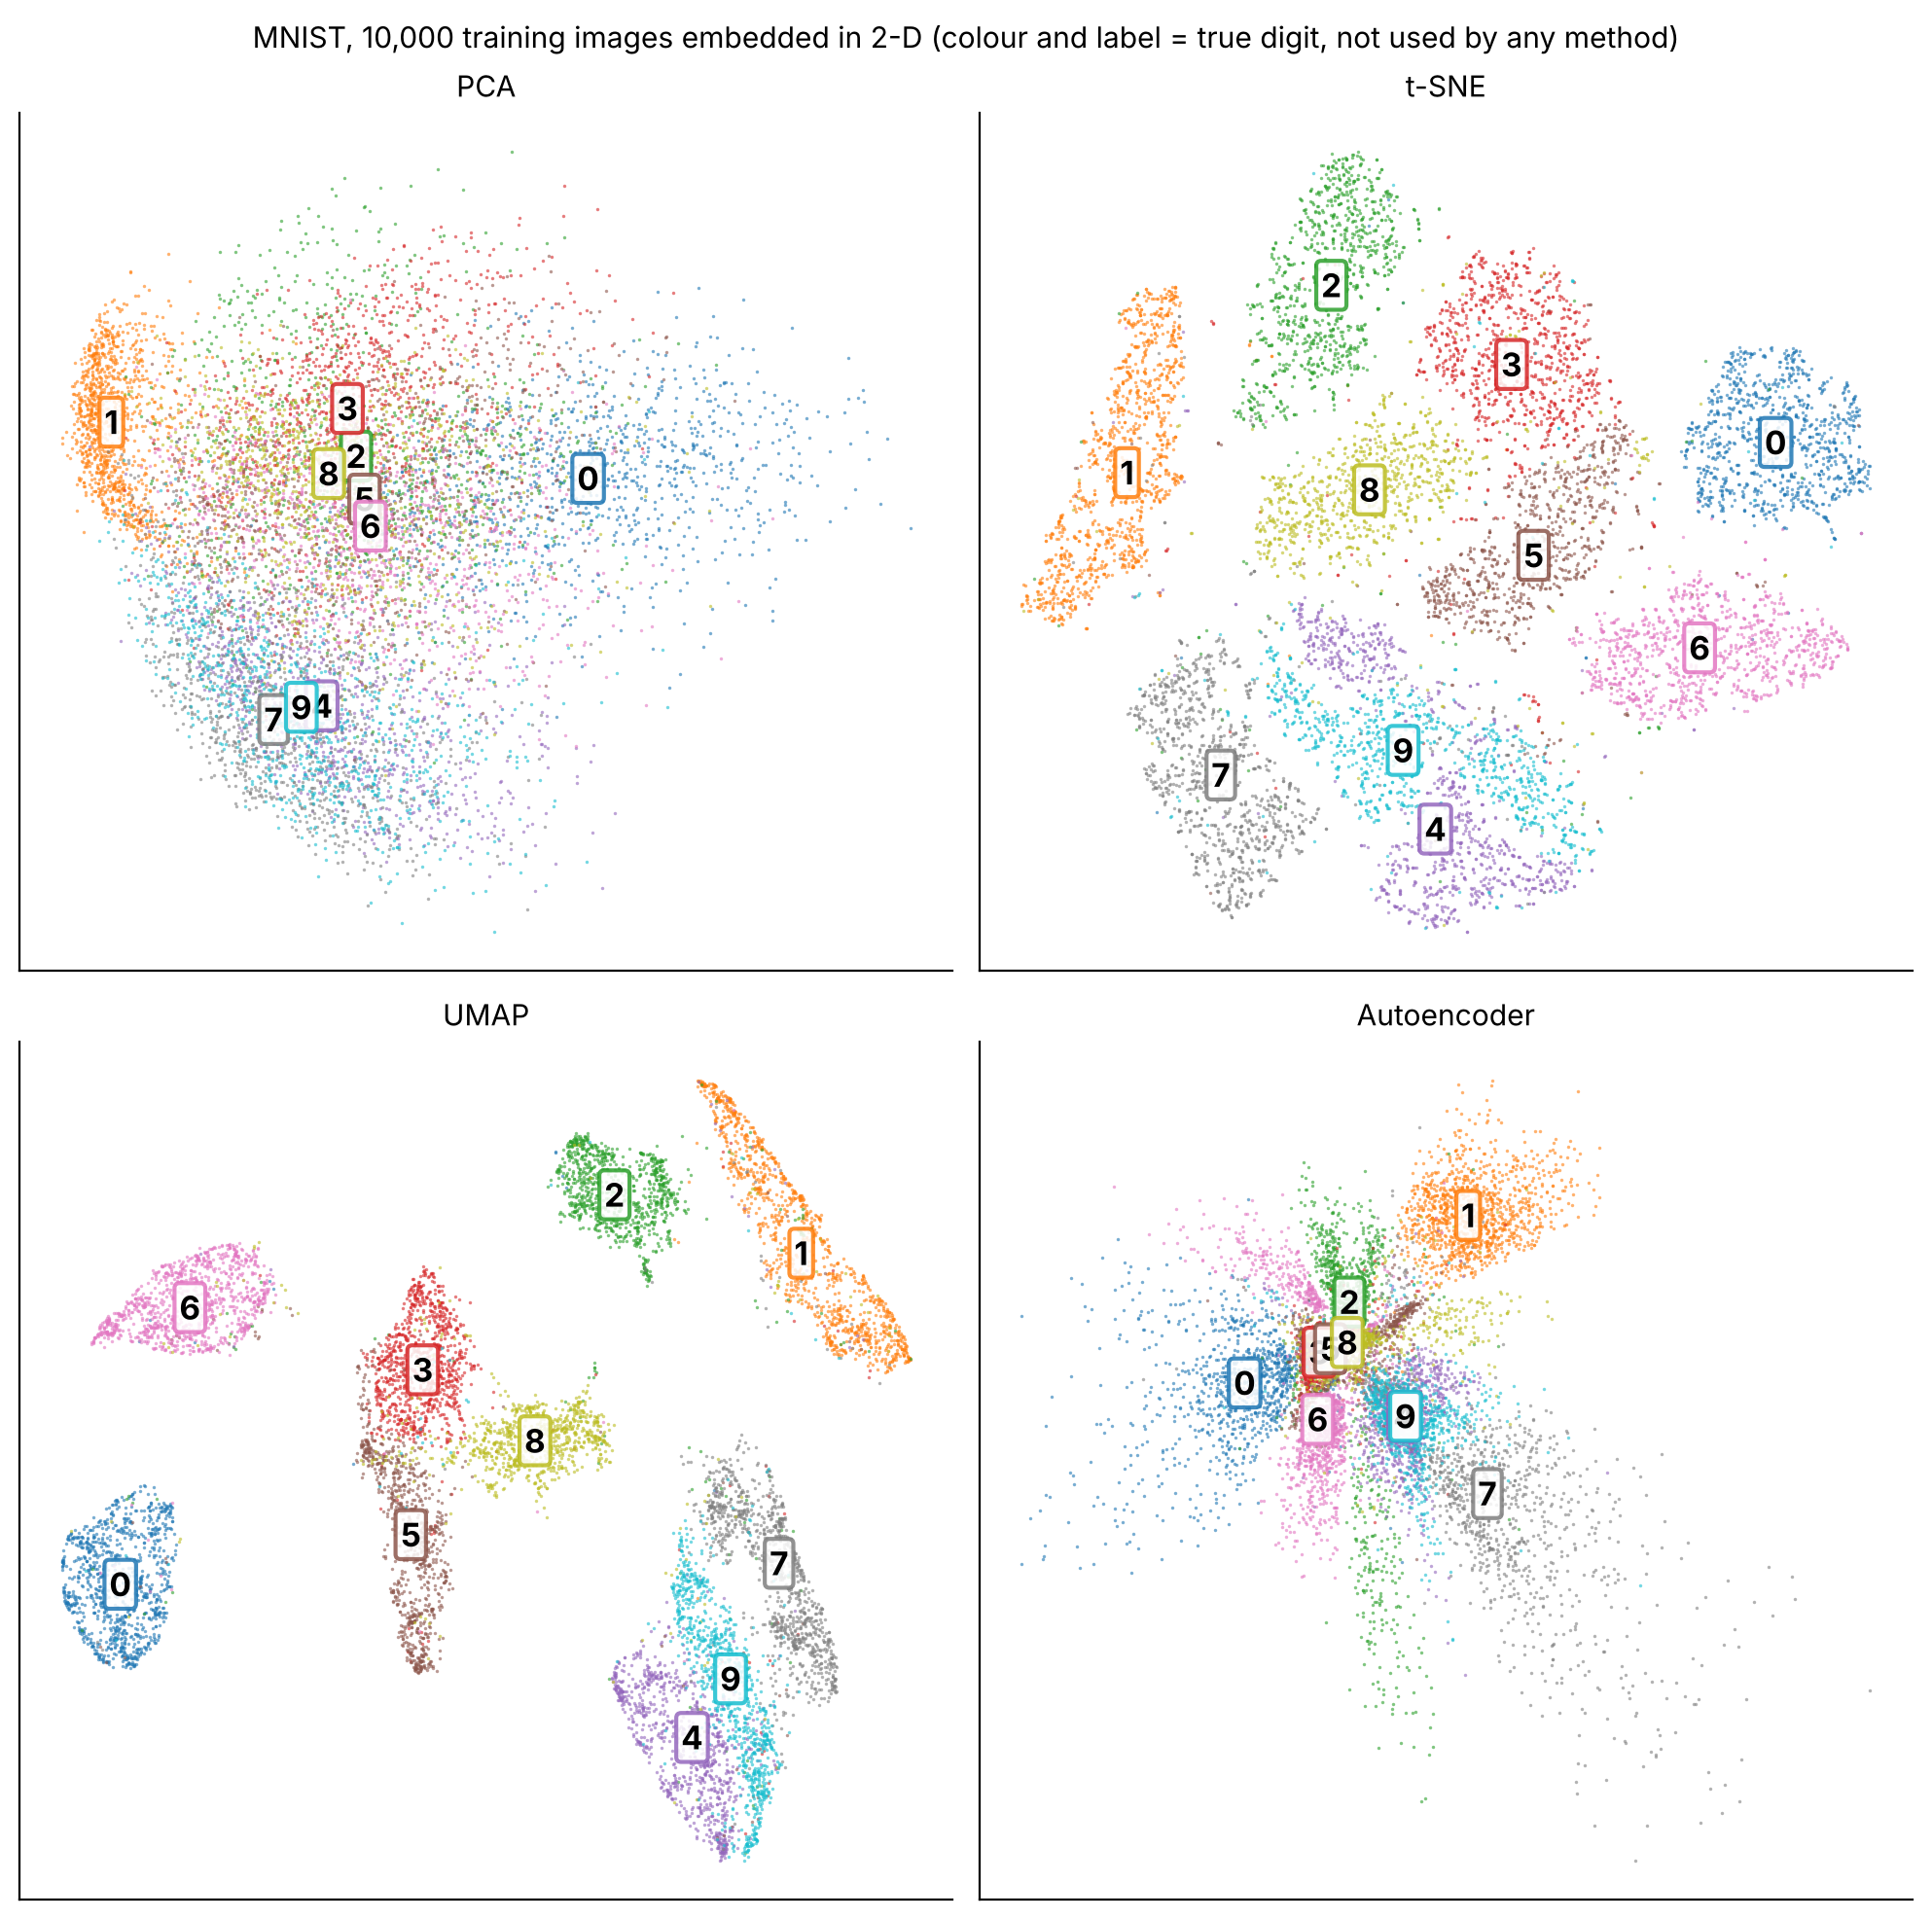

,trustworthiness@10,continuity@10,global distance corr.,kNN acc. (5-fold CV),kNN acc. on new test images,fit time (s),how new points are embedded
method,,,,,,,
PCA,0.732,0.923,0.458,0.414,0.422,0,linear projection
t-SNE,0.977,0.960,0.372,0.946,0.941,47,re-optimise against fixed map (openTSNE)
UMAP,0.952,0.966,0.323,0.925,0.918,36,learned graph -> transform()
Autoencoder,0.946,0.923,0.287,0.759,0.706,93,encoder network


In [4]:
# All four methods embed the SAME 10k MNIST sample into 2-D.
# PCA = the linear method from class (baseline). t-SNE runs on the first 50 PCs (standard practice:
# removes pixel noise and speeds up the neighbour search; 50 PCs keep ~83% of the variance).
emb, oos, fit_time = {}, {}, {}

t0 = time.time(); pca2 = PCA(2, random_state=SEED).fit(X)
emb["PCA"], oos["PCA"], fit_time["PCA"] = pca2.transform(X), pca2.transform(X_te), time.time() - t0

pca50 = PCA(50, random_state=SEED).fit(X)
print(f"variance kept by 50 PCs: {pca50.explained_variance_ratio_.sum():.3f}")
t0 = time.time(); tsne = TSNE(perplexity=30, n_jobs=N_JOBS, random_state=SEED).fit(pca50.transform(X))
fit_time["t-SNE"] = time.time() - t0
emb["t-SNE"] = np.asarray(tsne)
oos["t-SNE"] = np.asarray(tsne.transform(pca50.transform(X_te)))      # openTSNE: optimises new points against the fixed map

t0 = time.time(); um = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED).fit(X)
fit_time["UMAP"] = time.time() - t0
emb["UMAP"], oos["UMAP"] = um.embedding_, um.transform(X_te)

t0 = time.time(); ae2, hist_ae2 = train_ae(X, X_val, d=2, steps=6000)
fit_time["Autoencoder"] = time.time() - t0
emb["Autoencoder"], oos["Autoencoder"] = encode(ae2, X), encode(ae2, X_te)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, (name, Y) in zip(axes.ravel(), emb.items()):
    plot_embedding(ax, Y, y, name)
fig.suptitle("MNIST, 10,000 training images embedded in 2-D (colour and label = true digit, not used by any method)")
fig.tight_layout(); fig.savefig(OUT_DIR / "mnist_2d_embeddings.png", dpi=200); plt.show()

rows = []
for name, Y in emb.items():
    rows.append({"method": name,
                 "trustworthiness@10": trustworthiness(X[:N_EVAL], Y[:N_EVAL], n_neighbors=K_NB),
                 "continuity@10": continuity(X[:N_EVAL], Y[:N_EVAL]),
                 "global distance corr.": global_corr(X, Y),
                 "kNN acc. (5-fold CV)": knn_cv_acc(Y, y),
                 "kNN acc. on new test images": knn_oos_acc(Y, y, oos[name], y_te),
                 "fit time (s)": fit_time[name]})
mnist_table = pd.DataFrame(rows).set_index("method")
mnist_table["how new points are embedded"] = ["linear projection", "re-optimise against fixed map (openTSNE)",
                                             "learned graph -> transform()", "encoder network"]
display(mnist_table.style.format({c: "{:.3f}" for c in mnist_table.columns[:5]} | {"fit time (s)": "{:.0f}"}))
mnist_table.to_csv(OUT_DIR / "mnist_metrics.csv")


**What we see**
- **PCA** (the linear baseline) separates only 1 and 0. Digits 4/7/9 and 3/5/8 lie on top of each other, and $k$-NN accuracy in 2-D is 0.41. It has the *best* global distance correlation (0.46) but the *worst* trustworthiness (0.73): a linear projection puts images that are far apart in pixel space on top of each other (false neighbours).
- **t-SNE** finds ten well-separated groups: trustworthiness 0.977, $k$-NN accuracy 0.946. The groups that touch (4-9 and 3-5-8) are the digits that genuinely look alike. Its global distance correlation (0.37) is below PCA's, because where a cluster sits on the map is not meaningful.
- **UMAP** has similar quality (trustworthiness 0.952, the best continuity at 0.966, $k$-NN 0.925). Its clusters are tighter, with more white space, and similar digits are grouped into "super-clusters" {4, 7, 9} and {3, 5, 8}. It is faster than t-SNE here, 34 s vs 45 s.
- **The autoencoder with $d=2$** places the classes like spokes around the centre: 0, 1, 6 and 7 are separate, while 2/3/5/8 crowd near the origin. Its neighbours are mostly real (trustworthiness 0.946), but the classes overlap ($k$-NN 0.76). The reason is that the loss only asks for reconstruction. Nothing pushes clusters apart, and a 2-number code is a very tight bottleneck for a 784-pixel image.
- **Out-of-sample:** a $k$-NN classifier trained on the embedded sample and tested on *new* embedded test images loses only 0.4-5 points of accuracy. UMAP's `transform` and the autoencoder's encoder are real learned maps. For t-SNE, new points are placed by optimising them against the fixed map, which works but is a separate optimisation.

**Caution when reading t-SNE/UMAP plots:** cluster *sizes* and *distances between clusters* are not interpretable. The KL / cross-entropy objectives barely penalise moving far-apart groups.


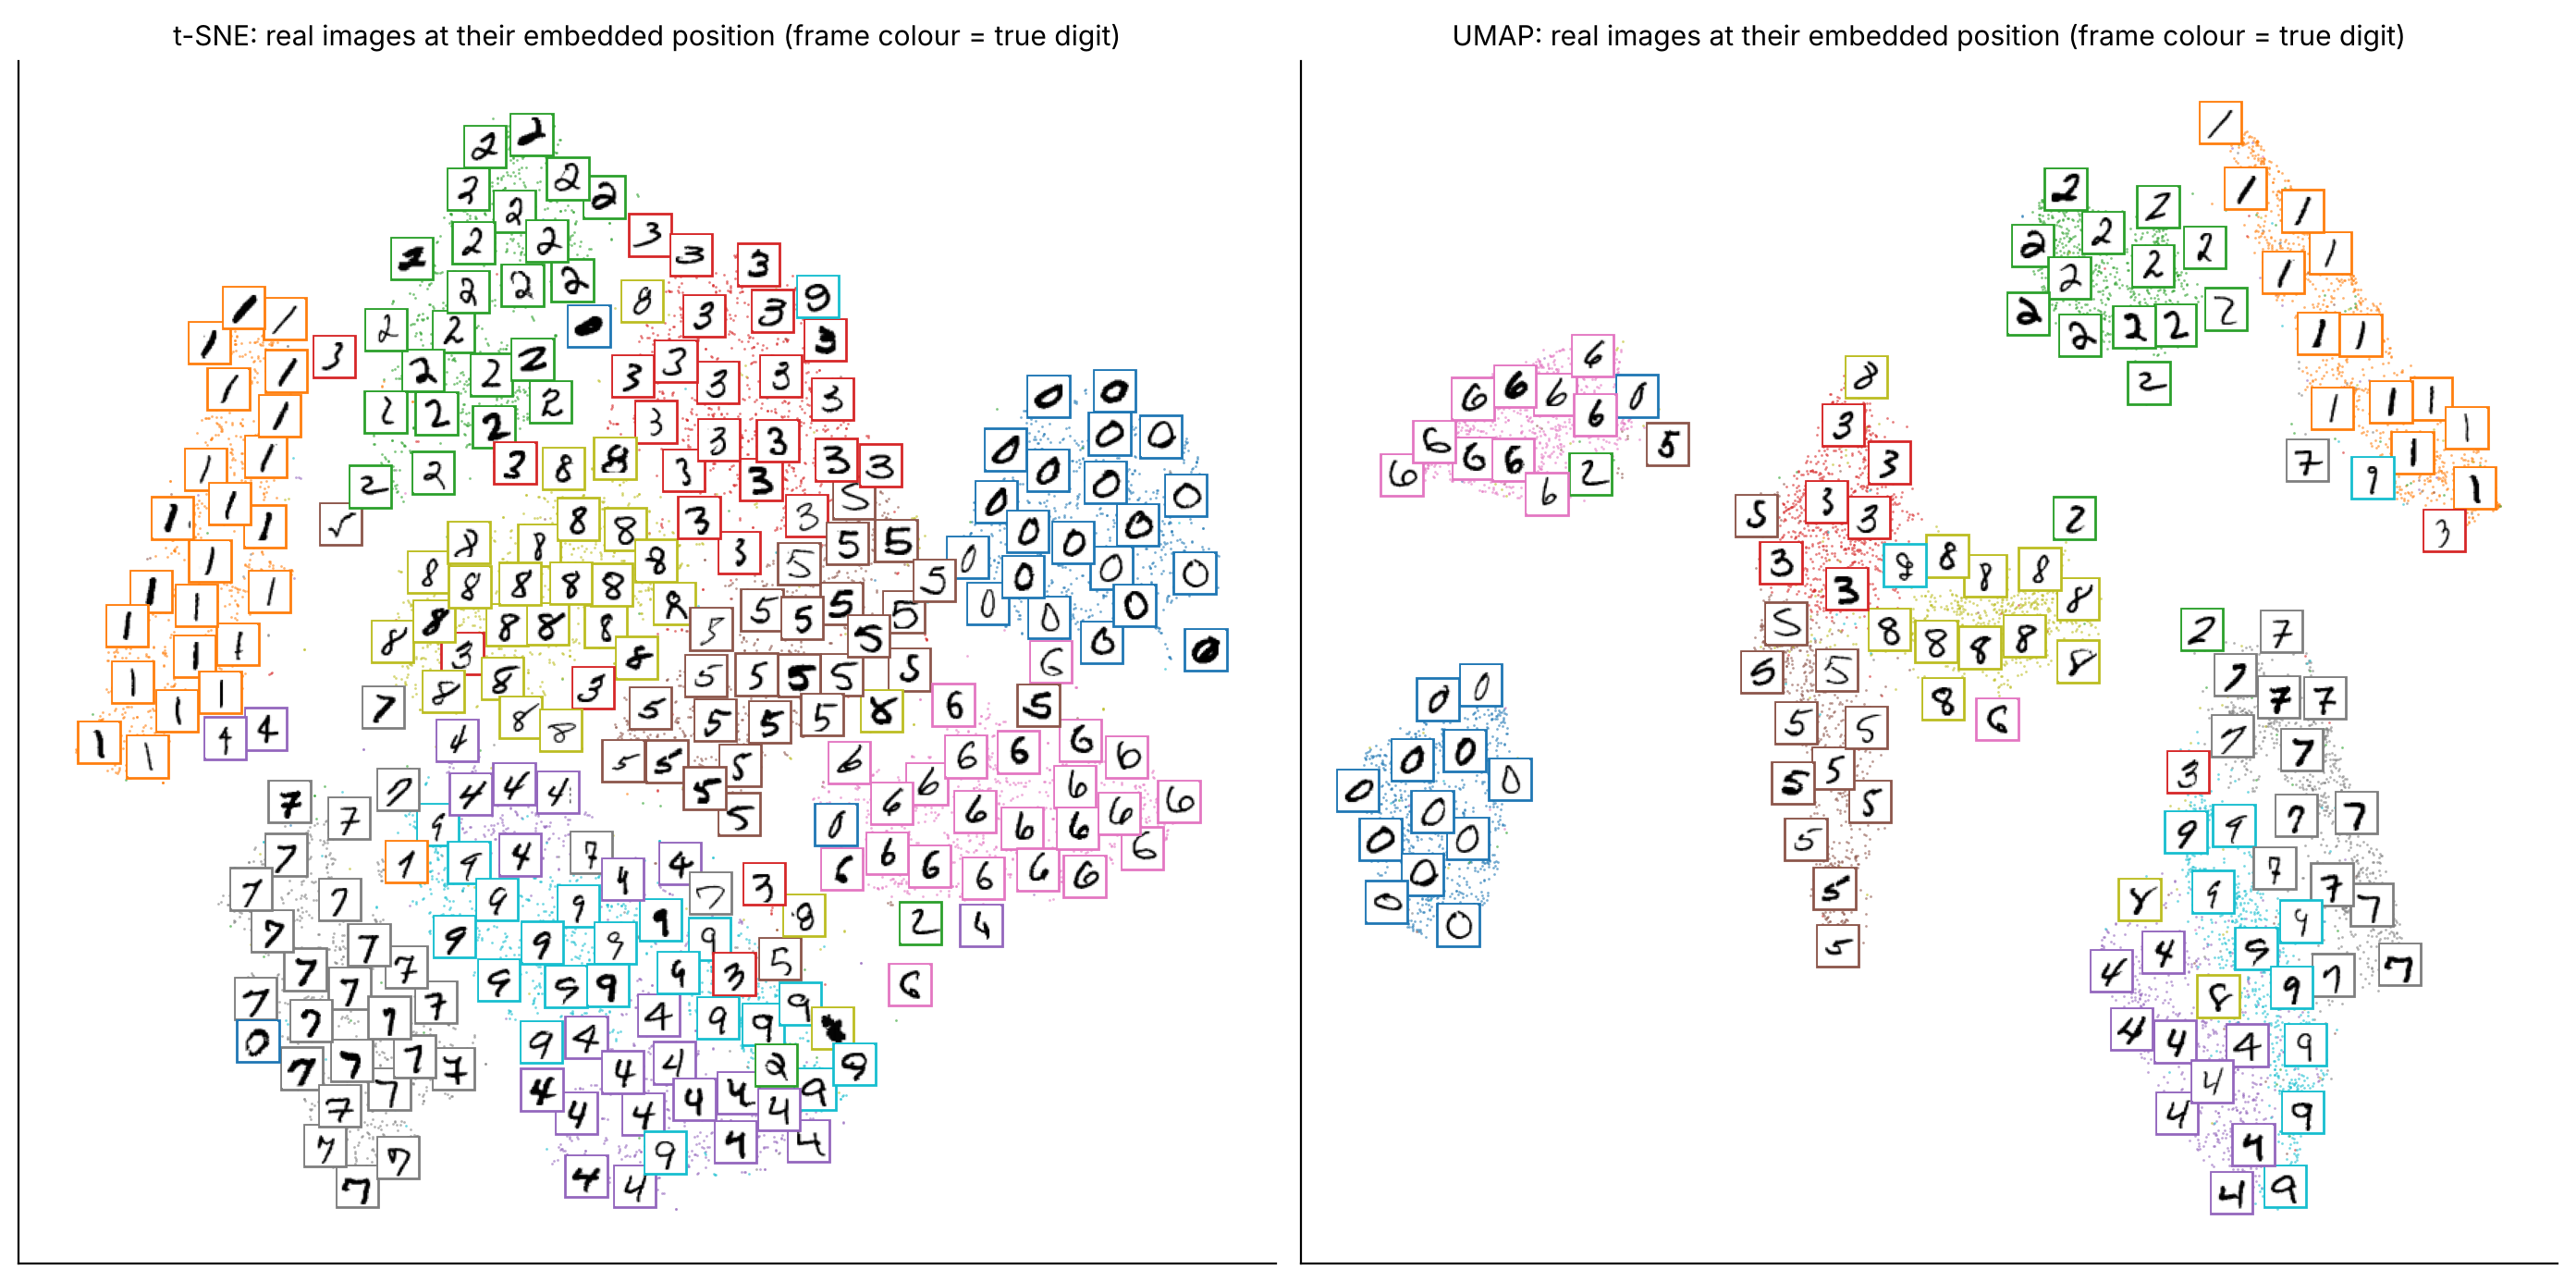

In [5]:
# What do the clusters and the points between them look like? Draw real digit images on the UMAP and t-SNE maps.
from matplotlib.offsetbox import OffsetImage, AnnotationBbox


def plot_thumbnails(ax, Y, images, labels, n_show=250, min_dist_frac=0.035, seed=SEED):
    plot_embedding(ax, Y, labels, "", s=1, label_clusters=False)
    span = np.ptp(Y, axis=0).max()
    shown = []
    for i in np.random.default_rng(seed).permutation(len(Y)):
        if len(shown) >= n_show:
            break
        if shown and np.min(np.linalg.norm(Y[shown] - Y[i], axis=1)) < min_dist_frac * span:
            continue                                   # keep thumbnails from overlapping
        shown.append(i)
        im = OffsetImage(images[i].reshape(28, 28), cmap="gray_r", zoom=0.55)
        ax.add_artist(AnnotationBbox(im, Y[i], frameon=True, pad=0.05,
                                     bboxprops=dict(edgecolor=DIGIT_COLORS[labels[i]], lw=1)))


fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, name in zip(axes, ["t-SNE", "UMAP"]):
    plot_thumbnails(ax, emb[name], X, y)
    ax.set_title(f"{name}: real images at their embedded position (frame colour = true digit)")
fig.tight_layout(); fig.savefig(OUT_DIR / "mnist_thumbnails.png", dpi=200); plt.show()


**Reading the maps with the real images.** Inside a cluster the position varies smoothly with *style*: the slant of the 1s, stroke thickness, open vs closed 4s. The points that sit in the "wrong" cluster are mostly ambiguous handwriting: 4s that look like 9s, a 7 among the 9s, a 3 written like a 5. The embedding is reflecting pixel similarity, not label errors.


## The locality hyperparameter: bias and variance

Perplexity sets $\sigma_i$ in t-SNE's Gaussian kernel, and `n_neighbors` = $k$ sets UMAP's $k$-NN graph. Both choose **how many neighbours define a point's neighbourhood**. This is the complexity knob the professor mentioned. We sweep both on a 3,000-image subset.


/usr/local/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


/usr/local/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


/usr/local/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


/usr/local/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


/usr/local/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


/usr/local/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


/usr/local/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


/usr/local/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


/usr/local/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


/usr/local/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


trustworthiness@10  global distance corr.  \
method param       value                                              
t-SNE  perplexity  2                   0.956                  0.317   
                   5                   0.972                  0.304   
                   30                  0.976                  0.383   
                   100                 0.970                  0.416   
                   300                 0.964                  0.500   
UMAP   n_neighbors 3                   0.954                  0.257   
                   5                   0.958                  0.357   
                   15                  0.952                  0.345   
                   50                  0.947                  0.383   
                   200                 0.929                  0.413   

                          kNN acc. (5-fold CV)  seed stability (shared 10-NN)  
method param       value                                                       
t-SNE  perplexity  2                     0.905                          0.721  
                   5                     0.924                          0.832  
                   30                    0.912                          0.788  
                   100                   0.892                          0.612  
                   300                   0.847                          0.540  
UMAP   n_neighbors 3                     0.888                          0.666  
                   5                     0.904                          0.630  
                   15                    0.878                          0.533  
                   50                    0.840                          0.559  
                   200                   0.802                          0.477

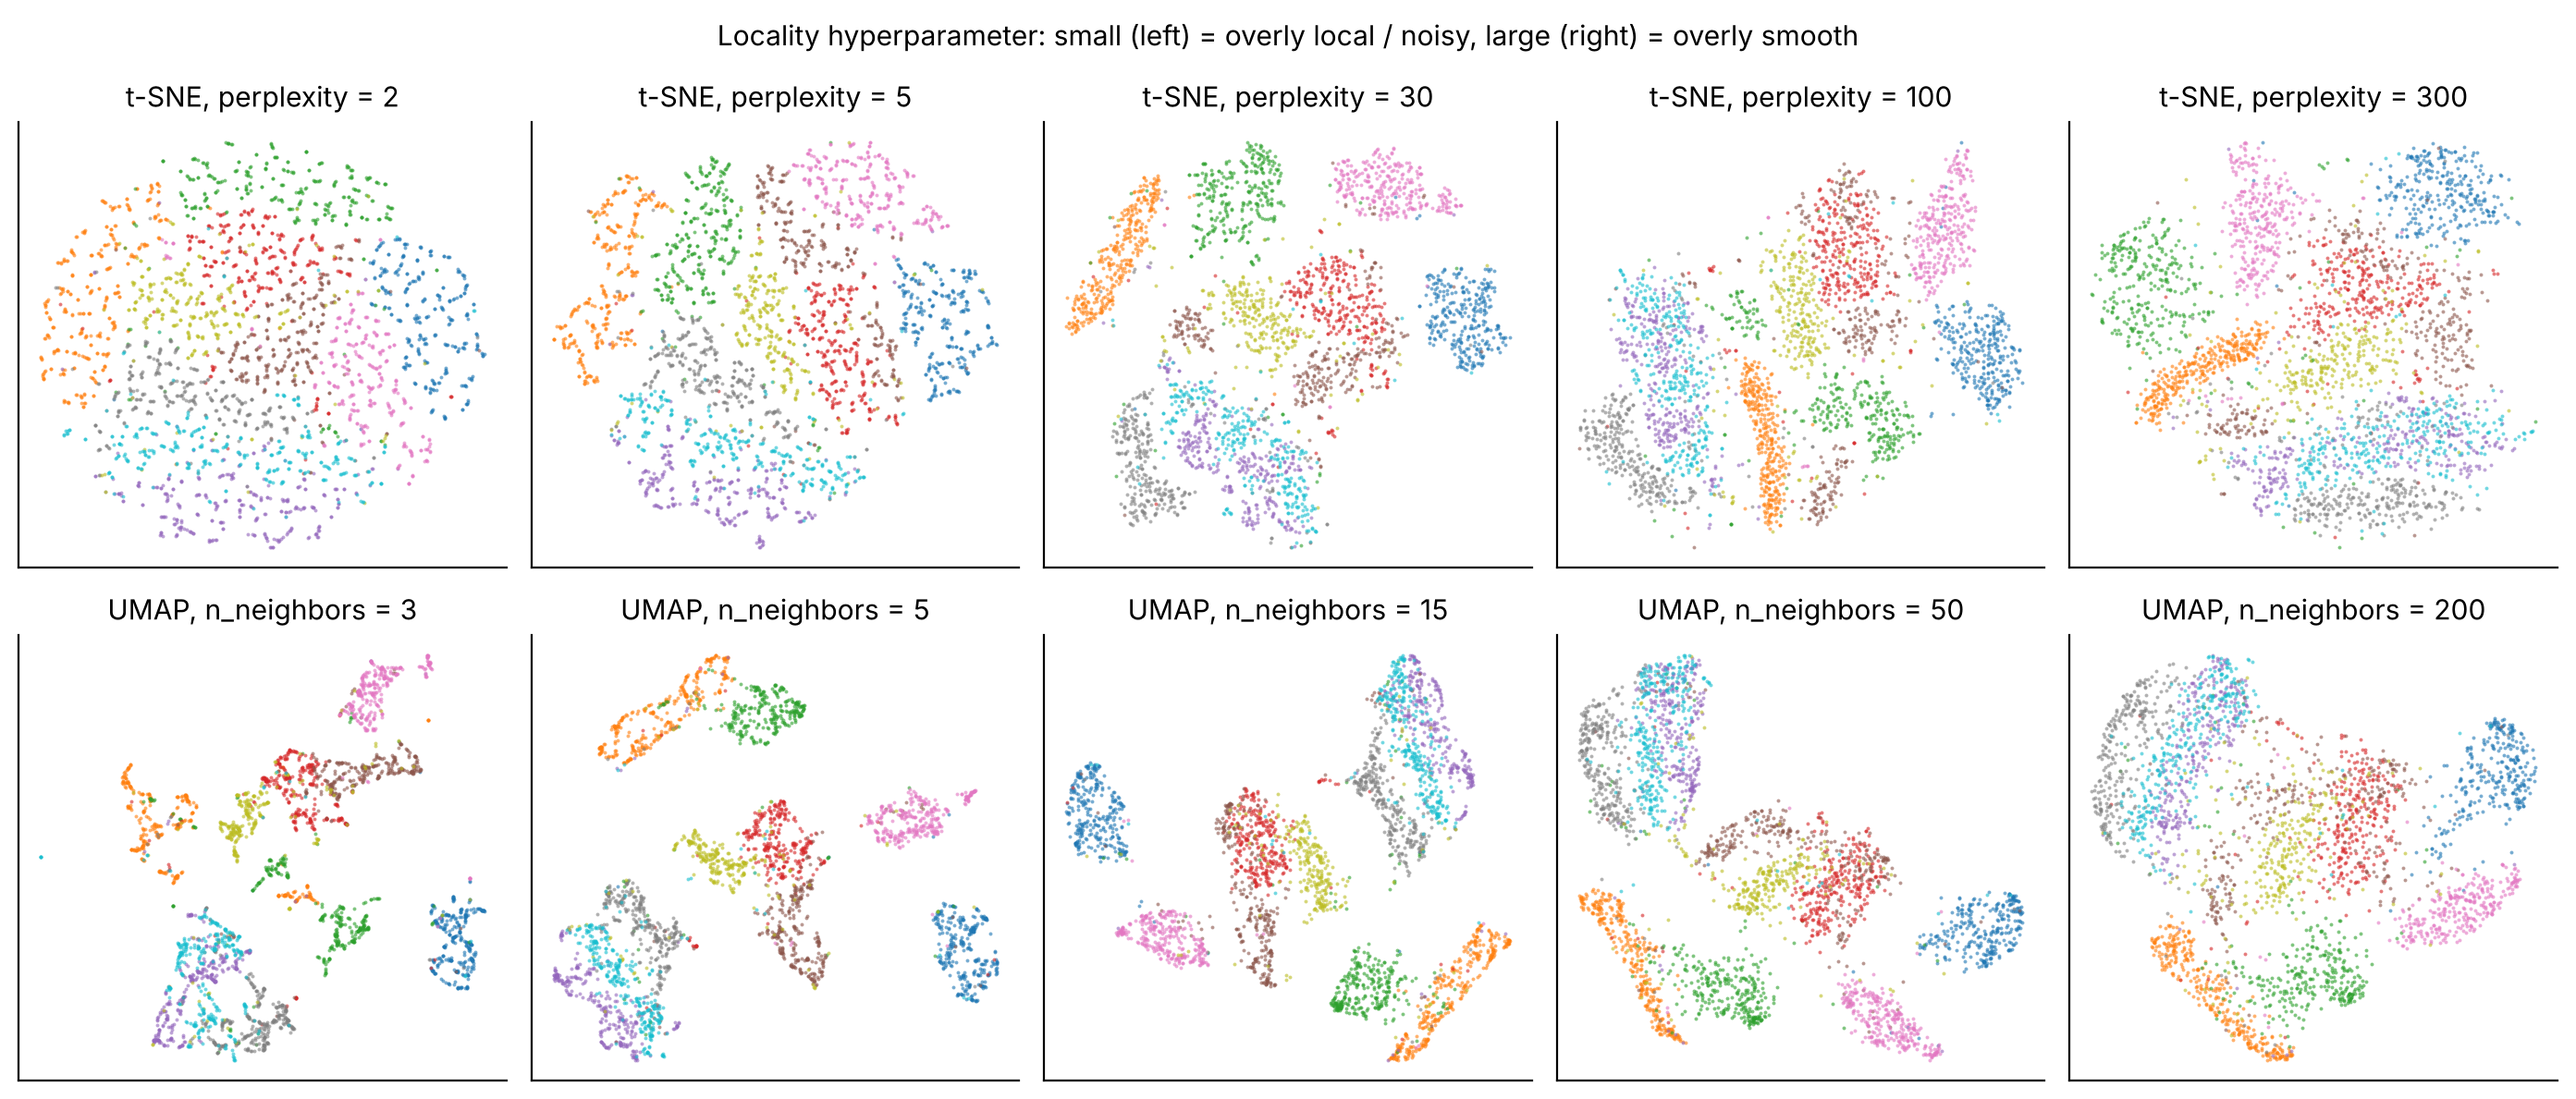

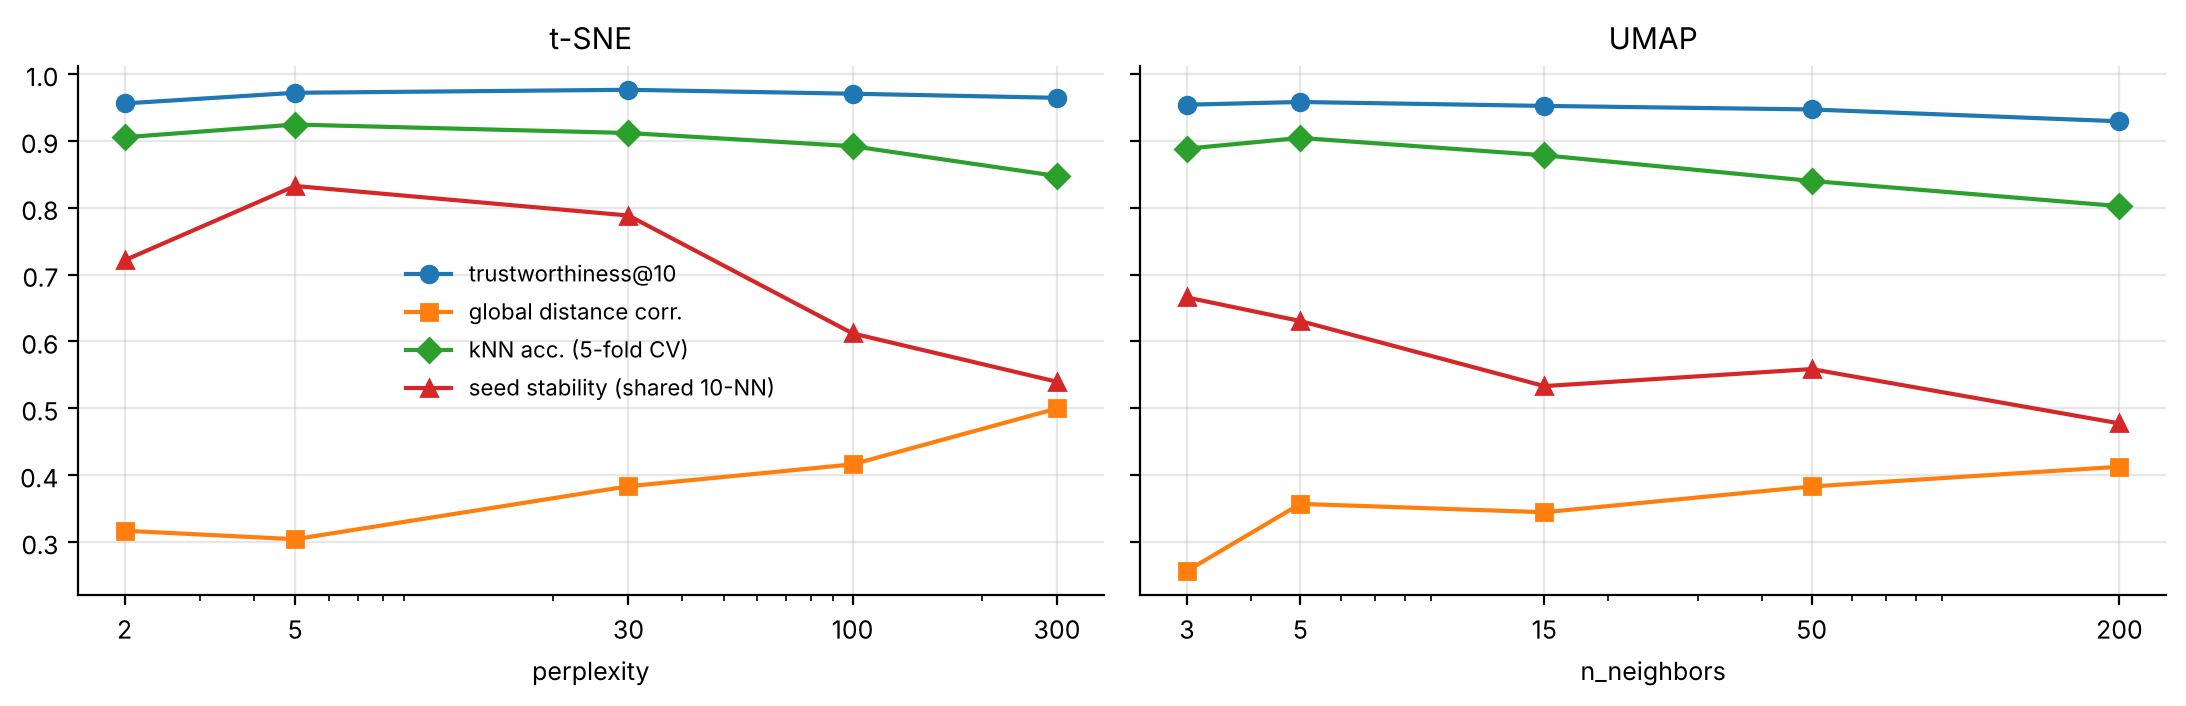

In [6]:
# Hyperparameter = locality knob. Small perplexity / n_neighbors: each point is described by very few
# neighbours -> the embedding follows noise (high variance, "overfitting"). Large: each point averages over
# many neighbours -> smooth but local detail is lost (high bias, "underfitting").
# Measured on a 3k subset, each setting run with two random seeds:
#   trustworthiness@10 (local fit), global distance corr. (global fit), kNN accuracy,
#   seed stability = shared 10-NN between the two seeds' embeddings (low = high variance).
X3, y3 = X[:3000], y[:3000]
P3 = pca50.transform(X3)
sweeps = {
    "t-SNE": ("perplexity", [2, 5, 30, 100, 300],
              lambda v, s: np.asarray(TSNE(perplexity=v, n_jobs=N_JOBS, random_state=s).fit(P3))),
    "UMAP": ("n_neighbors", [3, 5, 15, 50, 200],
             lambda v, s: umap.UMAP(n_neighbors=v, min_dist=0.1, random_state=s).fit_transform(X3)),
}
sweep_rows, sweep_emb = [], {}
for meth, (pname, values, fit) in sweeps.items():
    for v in values:
        Ya, Yb = fit(v, SEED), fit(v, SEED + 1)
        sweep_emb[(meth, v)] = Ya
        sweep_rows.append({"method": meth, "param": pname, "value": v,
                           "trustworthiness@10": trustworthiness(X3, Ya, n_neighbors=K_NB),
                           "global distance corr.": global_corr(X3, Ya),
                           "kNN acc. (5-fold CV)": knn_cv_acc(Ya, y3),
                           "seed stability (shared 10-NN)": knn_overlap(Ya, Yb)})
sweep_table = pd.DataFrame(sweep_rows)
display(sweep_table.set_index(["method", "param", "value"]).round(3))
sweep_table.to_csv(OUT_DIR / "sweeps.csv", index=False)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for r, (meth, (pname, values, _)) in enumerate(sweeps.items()):
    for c, v in enumerate(values):
        plot_embedding(axes[r, c], sweep_emb[(meth, v)], y3, f"{meth}, {pname} = {v}", s=2, label_clusters=False)
fig.suptitle("Locality hyperparameter: small (left) = overly local / noisy, large (right) = overly smooth")
fig.tight_layout(); fig.savefig(OUT_DIR / "sweeps_embeddings.png", dpi=200); plt.show()

metrics = ["trustworthiness@10", "global distance corr.", "kNN acc. (5-fold CV)", "seed stability (shared 10-NN)"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (meth, (pname, values, _)) in zip(axes, sweeps.items()):
    d = sweep_table[sweep_table.method == meth]
    for m, mk in zip(metrics, "osD^"):
        ax.plot(d.value, d[m], marker=mk, lw=1.5, label=m)
    ax.set_xscale("log"); ax.set_xticks(values); ax.set_xticklabels(values)
    ax.set_xlabel(pname); ax.set_title(meth); ax.grid(alpha=0.3)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "sweeps_metrics.png", dpi=200); plt.show()


**What the sweep shows**
- **Too local (perplexity 2, $k=3$): overfitting to sampling noise.** t-SNE spreads the points almost uniformly over a disc, and the clusters are barely visible. With $k=3$, UMAP's graph falls apart, so one digit is split into several islands (the 1s and the 2s). These islands are *spurious structure* created by which points happened to be sampled.
- **Too smooth (perplexity 300, $k=200$): underfitting.** The clusters merge ({4, 7, 9} and {3, 5, 8} become blobs). Trustworthiness and $k$-NN accuracy fall: for t-SNE, $k$-NN goes from 0.92 to 0.85, and for UMAP from 0.90 to 0.80. Meanwhile the global distance correlation rises (t-SNE 0.30 → 0.50, UMAP 0.26 → 0.41). The map is trading local detail for global shape.
- **In between** (perplexity 5-30, $k$ = 5-15), local quality and class separation are best. The library defaults (30 and 15) are reasonable for MNIST.
- **Seed stability** (shared 10-NN between two seeds) is highest at moderate values (t-SNE 0.83 at perplexity 5) and drops on both sides. At the small end that is variance. At the large end, the merged blobs have no well-defined local ordering, so it is not a pure variance measure. We should present it as such.

**Link to the course.** Unlike supervised learning, there is no test error to validate against. The "best" hyperparameter depends on the criterion: local criteria favour small values, global ones favour large values. This is the professor's first point, that there is no universal benchmark. A reasonable protocol is to fix the criterion that matches the task first (for example $k$-NN accuracy with cross-validation if the goal is class structure), then choose the hyperparameter by that criterion. The same should be done for every method in the group.


## The autoencoder as a learning problem

The autoencoder is the one method in this part with a real training/validation split: it minimises an empirical risk over a parametric family. That makes it the natural place for the course concepts: comparison with PCA, capacity, overfitting and regularisation.


Test-set reconstruction MSE per pixel (lower is better)


,PCA,linear AE,nonlinear AE,AE error / PCA error
d,,,,
2,0.0557,0.0558,0.0367,0.6586
8,0.0374,0.0376,0.0153,0.4079
32,0.0168,0.0170,0.0059,0.3502


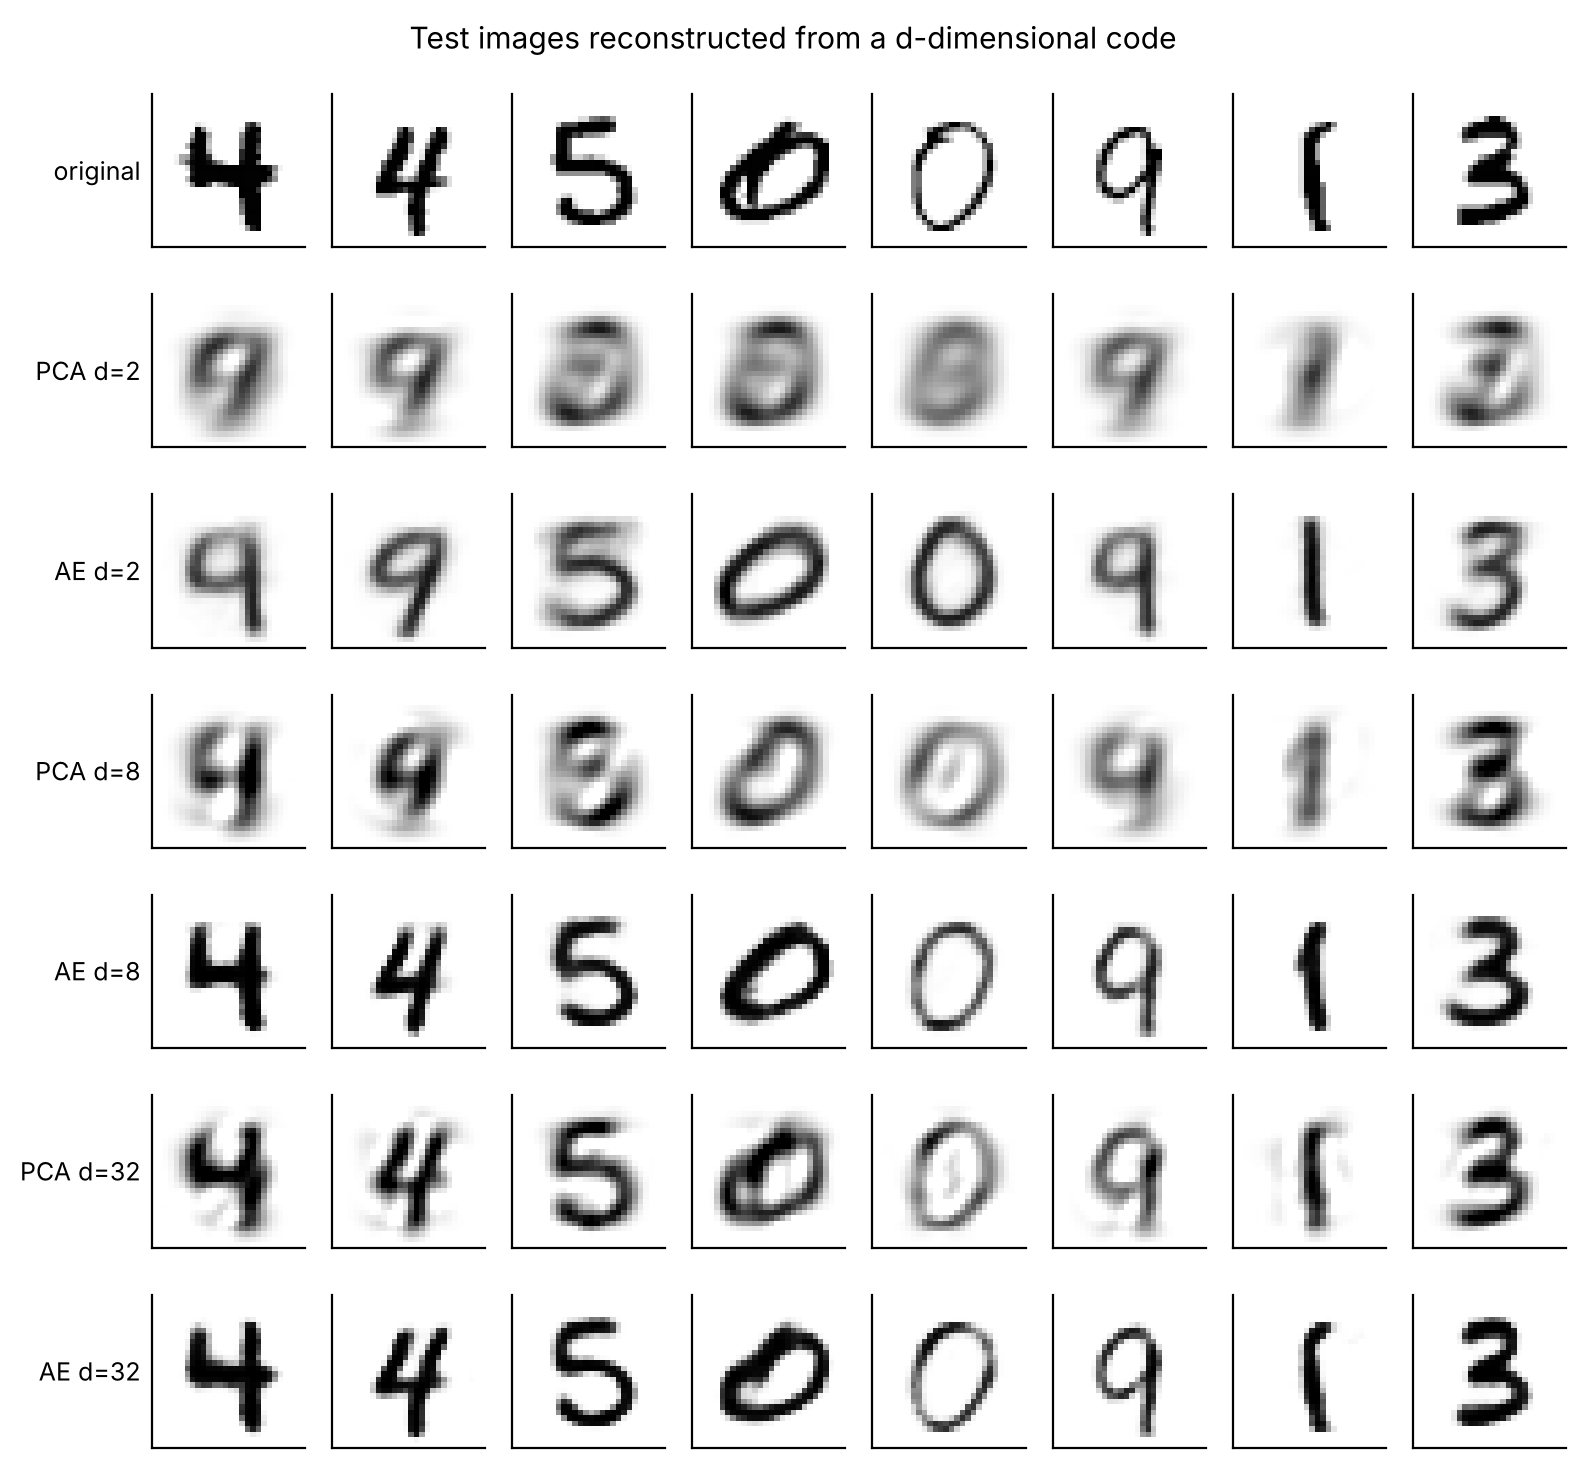

In [7]:
# (i) Autoencoder vs PCA at the same latent dimension d, trained on 50k images (all training data except
# the 10k validation images), evaluated on the 10k MNIST test images. The linear autoencoder (no
# activations) is the check that a linear AE learns the PCA subspace, so its error should match PCA's.
train_full_idx = np.setdiff1d(np.arange(len(X_train)), val_idx)
X_tr50 = X_train[train_full_idx]
DIMS = [2, 8, 32]
ae_models, rec_rows = {}, []
for d in DIMS:
    pca_d = PCA(d, random_state=SEED).fit(X_tr50)
    pca_mse = np.mean((pca_d.inverse_transform(pca_d.transform(X_test)) - X_test) ** 2)
    lin, _ = train_ae(X_tr50, X_val, d, steps=6000, linear=True)
    ae_models[d], _ = train_ae(X_tr50, X_val, d, steps=6000)
    rec_rows.append({"d": d, "PCA": pca_mse, "linear AE": recon_mse(lin, X_test),
                     "nonlinear AE": recon_mse(ae_models[d], X_test)})
rec_table = pd.DataFrame(rec_rows).set_index("d")
rec_table["AE error / PCA error"] = rec_table["nonlinear AE"] / rec_table["PCA"]
print("Test-set reconstruction MSE per pixel (lower is better)")
display(rec_table.round(4))
rec_table.to_csv(OUT_DIR / "ae_vs_pca_reconstruction.csv")

show = np.random.default_rng(SEED).choice(len(X_test), 8, replace=False)
fig, axes = plt.subplots(1 + 2 * len(DIMS), 8, figsize=(8, 7.5))
rows_img = [("original", X_test[show])]
for d in DIMS:
    pca_d = PCA(d, random_state=SEED).fit(X_tr50)
    rows_img.append((f"PCA d={d}", pca_d.inverse_transform(pca_d.transform(X_test[show]))))
    with torch.no_grad():
        rows_img.append((f"AE d={d}", ae_models[d](torch.tensor(X_test[show])).numpy()))
for r, (lab, imgs) in enumerate(rows_img):
    for c in range(8):
        axes[r, c].imshow(np.clip(imgs[c], 0, 1).reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Test images reconstructed from a d-dimensional code")
fig.tight_layout(); fig.savefig(OUT_DIR / "ae_reconstructions.png", dpi=200); plt.show()


**Autoencoder vs PCA**
- The **linear autoencoder matches PCA** to three decimals at every $d$ (0.0558 vs 0.0557 at $d=2$, 0.0170 vs 0.0168 at $d=32$). This is the Baldi-Hornik result: without non-linearities, an autoencoder is PCA.
- The **non-linear autoencoder** reduces test reconstruction error by 34% ($d=2$), 59% ($d=8$) and 65% ($d=32$). The digits lie near a *curved* low-dimensional set, which a linear subspace can only approximate with many more dimensions.
- The two methods fail differently. PCA at $d=2$ produces blurry blends of several digits. The autoencoder at $d=2$ produces a *sharp but sometimes wrong* digit (the 4s come back as 9s): its decoder outputs a typical digit for a region of the code. At $d=8$ the reconstructions are already very close.
- The autoencoder has about 1M parameters against $784\,d$ for PCA. That extra capacity is exactly what makes validation necessary (next cell).


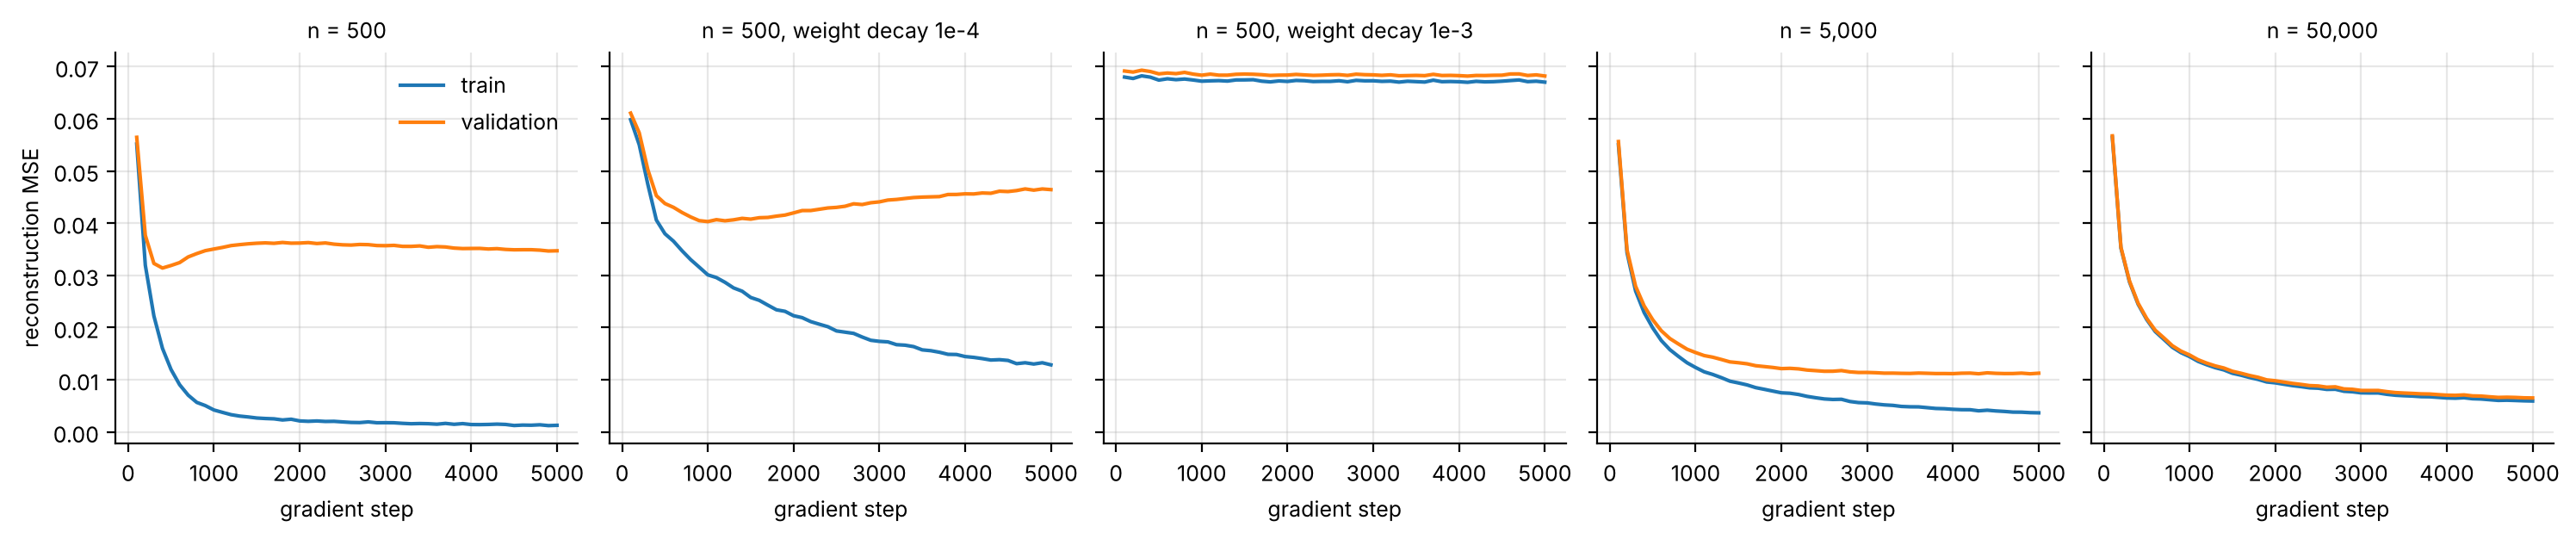

,final train MSE,final val MSE,best val MSE,step of best val (early stop)
run,,,,
n = 500,0.0013,0.0347,0.0314,400
"n = 500, weight decay 1e-4",0.0129,0.0464,0.0403,1000
"n = 500, weight decay 1e-3",0.0670,0.0682,0.0682,4100
"n = 5,000",0.0037,0.0113,0.0111,4900
"n = 50,000",0.0059,0.0065,0.0065,5000


In [8]:
# (ii) Overfitting. Same network (d = 32, ~1M parameters), trained for the same number of gradient steps on
# 500, 5,000 or 50,000 images, validated on the same 10k held-out images. With few images the network
# can memorise them: training error keeps falling while validation error turns up. We compare three remedies:
# weight decay (an L2 penalty, as in ridge regression), early stopping, and more data.
runs = {"n = 500": dict(n=500), "n = 500, weight decay 1e-4": dict(n=500, weight_decay=1e-4),
        "n = 500, weight decay 1e-3": dict(n=500, weight_decay=1e-3),
        "n = 5,000": dict(n=5_000), "n = 50,000": dict(n=50_000)}
curves, final = {}, []
for name, cfg in runs.items():
    Xtr = X_tr50[np.random.default_rng(SEED).choice(len(X_tr50), cfg["n"], replace=False)]
    model, h = train_ae(Xtr, X_val, d=32, steps=5000, weight_decay=cfg.get("weight_decay", 0.0), early_stop=False)
    curves[name] = h
    best = h.loc[h.val_mse.idxmin()]
    final.append({"run": name, "final train MSE": h.train_mse.iloc[-1], "final val MSE": h.val_mse.iloc[-1],
                  "best val MSE": best.val_mse, "step of best val (early stop)": int(best.step)})

fig, axes = plt.subplots(1, len(runs), figsize=(15, 3.2), sharey=True)
for ax, (name, h) in zip(axes, curves.items()):
    ax.plot(h.step, h.train_mse, lw=1.5, label="train")
    ax.plot(h.step, h.val_mse, lw=1.5, label="validation")
    ax.set_title(name, fontsize=9); ax.set_xlabel("gradient step"); ax.grid(alpha=0.3)
axes[0].set_ylabel("reconstruction MSE"); axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT_DIR / "ae_overfitting.png", dpi=200); plt.show()
display(pd.DataFrame(final).set_index("run").round(4))


**Overfitting and regularisation**
- **$n=500$, no regularisation:** a textbook overfit. Training error falls to 0.001 while validation error bottoms out at 0.031 after only 400 steps and then *rises* to 0.035. The network memorises its 500 images.
- **More data is the strongest regulariser.** With the same network and the same number of steps, the final validation error is 0.035 ($n=500$), 0.011 ($n=5{,}000$) and 0.0065 ($n=50{,}000$). At $n=50{,}000$ the training and validation curves are on top of each other.
- **Weight decay (L2)** shrinks the generalisation gap, but here it does so by raising the training error, not by lowering the validation error. With $\lambda=10^{-4}$ the validation error is *worse* than without it. With $\lambda=10^{-3}$ the network collapses to roughly the average image: training error = validation error ≈ 0.068, which is pure underfitting (high bias). In a separate check, $\lambda \in \{10^{-5}, 3\cdot10^{-5}, 10^{-4}, 3\cdot10^{-4}\}$ gave final validation errors of 0.033, 0.038, 0.046 and 0.065, so no value beat the unregularised run.
- **Early stopping** is the remedy that works: stopping at the minimum of the validation curve gives 0.031, the best result for $n=500$. All other autoencoders in this notebook use it.

This is the bias-variance trade-off in its usual form. Capacity (about 1M parameters) and the amount of data determine the variance. Regularisation strength trades variance for bias, and the right amount has to be chosen on held-out data, never on the training error. One caveat: Adam's `weight_decay` is a coupled L2 penalty. AdamW (decoupled) or a denoising autoencoder are the standard alternatives if we want to push this further.


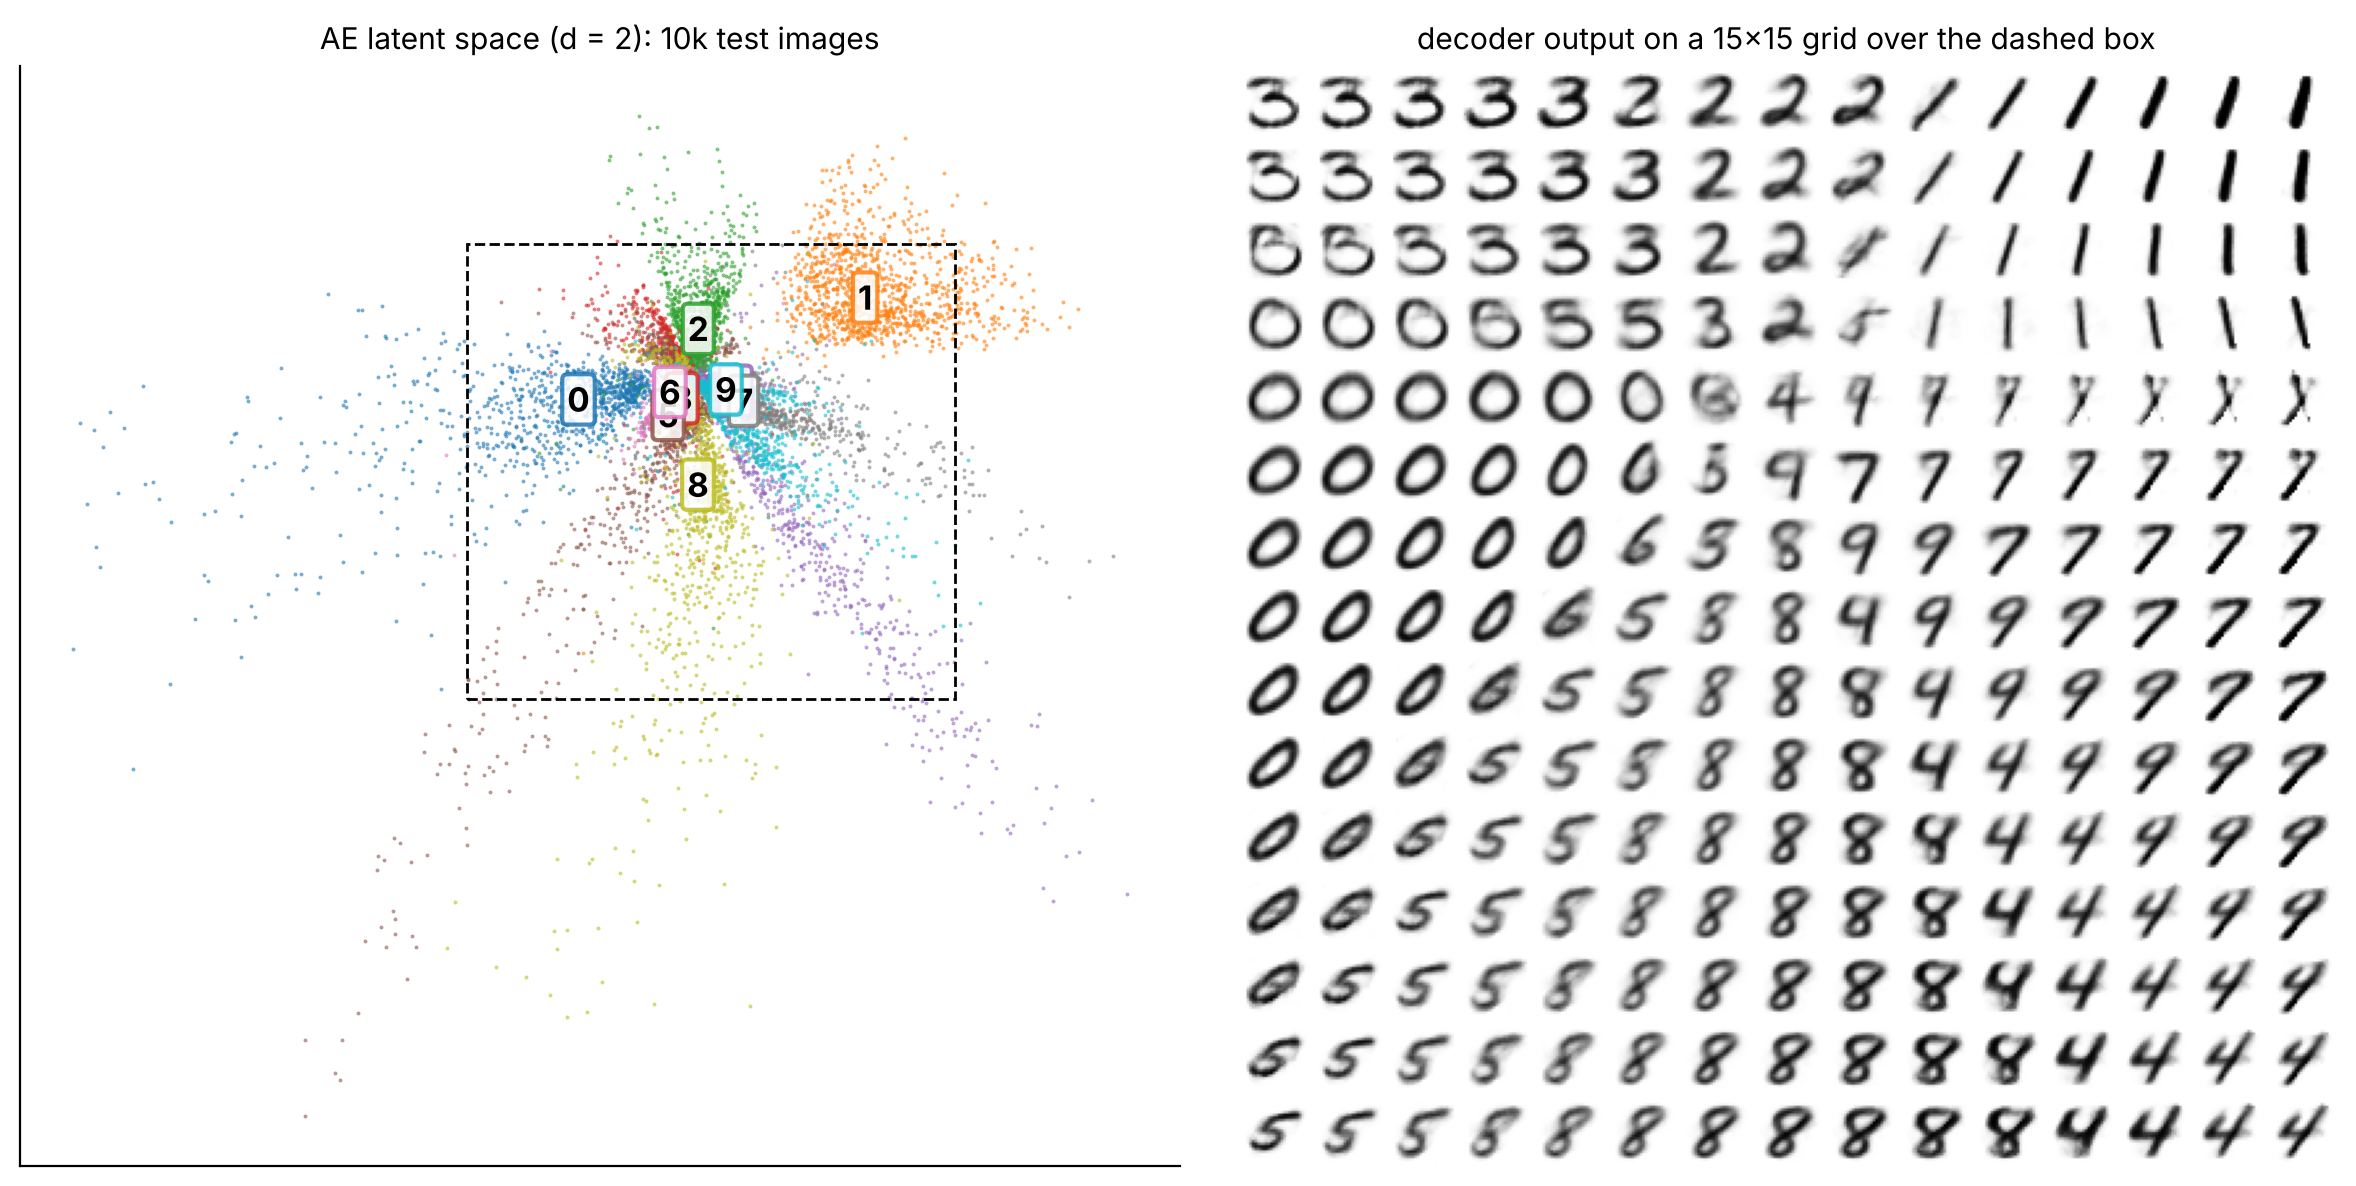

In [9]:
# (iii) The decoder is a generative map: decode a grid of points of the 2-D latent space (AE with d = 2,
# trained on 50k images). Left: test images encoded. Right: what the decoder draws at each grid point.
Z_te = encode(ae_models[2], X_test)
lo, hi = np.percentile(Z_te, [2, 98], axis=0)
G = 15
gx, gy = np.linspace(lo[0], hi[0], G), np.linspace(lo[1], hi[1], G)
grid = np.array([[a, b] for b in gy[::-1] for a in gx], dtype=np.float32)
with torch.no_grad():
    dec = ae_models[2].decoder(torch.tensor(grid)).numpy().reshape(G, G, 28, 28)
mosaic = dec.transpose(0, 2, 1, 3).reshape(G * 28, G * 28)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
plot_embedding(axes[0], Z_te, y_test, "AE latent space (d = 2): 10k test images", s=2)
axes[0].add_patch(plt.Rectangle(lo, *(hi - lo), fill=False, ls="--", lw=1, color="k"))
axes[1].imshow(mosaic, cmap="gray_r")
axes[1].set_title("decoder output on a 15x15 grid over the dashed box"); axes[1].axis("off")
fig.tight_layout(); fig.savefig(OUT_DIR / "ae_latent_grid.png", dpi=200); plt.show()


**The decoder is a map back to images.** Moving across the 2-D code smoothly morphs one digit into the next: 0 → 6 → 5 → 8, 9 ↔ 4 ↔ 7, and the 1s rotate from slanted to upright. Neighbouring classes in the code are the digits that share strokes. This is what t-SNE and UMAP cannot do: they give coordinates, not a map in either direction. It is also the starting point of variational autoencoders (Kingma & Welling, 2014; Doersch, 2016), which regularise the code so that *every* point of the latent space decodes to a plausible image.


## Summary: talking points for the presentation

1. **There is no single score.** Each method optimises a different notion of "structure", so we report local (trustworthiness, continuity), global (distance correlation), downstream ($k$-NN accuracy, also on new images) and reconstruction criteria side by side.
2. **t-SNE**: best local structure and class separation on MNIST ($k$-NN 0.95 in 2-D, against 0.41 for PCA). It does not preserve global geometry (the Swiss roll is torn apart), and it has no mapping for new points.
3. **UMAP**: almost as good locally, keeps more large-scale organisation (super-clusters {4, 7, 9} and {3, 5, 8}, the Swiss roll as one strip), is faster, and can embed new points. It is initialised with Laplacian eigenmaps.
4. **Autoencoder**: a non-linear PCA. The linear version reproduces PCA exactly, and the non-linear one cuts reconstruction error by 34-65%. In 2-D its classes overlap more, because reconstruction, not neighbourhood, is what it optimises. It is the only method with an explicit map in both directions, so it can also generate images.
5. **Hyperparameters = bias-variance.** Small perplexity or $k$ gives spurious islands and noise (overfitting). Large values merge the clusters and favour global over local structure (underfitting). For the autoencoder: with little data it overfits, early stopping and more data fix it, and too much weight decay underfits.
6. **Next step for the group:** run the other methods (kernel PCA, Isomap, LLE, Laplacian eigenmaps) through the same criteria and the same Swiss roll / MNIST sample. Isomap should be the one that unrolls the Swiss roll, which our three methods do not.
